# Etapa 2 — Análise Exploratória de Dados

Entrada: os CSVs que a Etapa 1 gravou em `../data/raw/`.
Saída: uma tabela horária limpa em `../data/processed/dataset.csv`, mais os
gráficos e as conclusões que sustentam o que você vai afirmar.

As seções abaixo são um roteiro, não uma receita. Responda as perguntas de
cada uma com código e, no fim, em texto. Acrescente seções se quiser.

In [26]:
from pathlib import Path

DIR_RAW = Path("..") / "data" / "raw"
DIR_PROC = Path("..") / "data" / "processed"
DIR_PROC.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import seaborn as sns

## 1. Carregar os CSVs

Leia os quatro arquivos de `../data/raw/`.

- Quantas linhas tem cada um? O número faz sentido para o período coletado?
- Os tipos vieram certos, ou datas e números chegaram como texto?
- Há colunas vazias, ou linhas duplicadas?

In [4]:
import pandas as pd
from pathlib import Path

data_path = Path("../data/raw")

# Localiza os quatro arquivos CSV
csv_files = list(data_path.glob("*.csv"))

In [5]:
for file in csv_files:
    print("\n" + "=" * 60)
    print(f"ARQUIVO: {file.name}")
    print("=" * 60)

    df = pd.read_csv(file)

    # 1. Quantidade de linhas e colunas
    print(f"\nDimensões: {df.shape}")
    print(f"Quantidade de linhas: {len(df)}")
    print(f"Quantidade de colunas: {len(df.columns)}")

    # 2. Tipos de dados
    print("\nTipos de dados:")
    print(df.dtypes)

    # 3. Valores ausentes
    print("\nValores ausentes por coluna:")
    print(df.isnull().sum())

    # 4. Colunas completamente vazias
    empty_columns = df.columns[df.isnull().all()].tolist()
    print("\nColunas completamente vazias:")
    print(empty_columns)

    # 5. Linhas duplicadas
    duplicates = df.duplicated().sum()
    print(f"\nQuantidade de linhas duplicadas: {duplicates}")

    # 6. Resumo estatístico
    print("\nResumo estatístico:")
    print(df.describe(include="all"))



ARQUIVO: mares_2025.csv

Dimensões: (1410, 10)
Quantidade de linhas: 1410
Quantidade de colunas: 10

Tipos de dados:
data               str
hora               str
altura_m       float64
tipo               str
coeficiente      int64
coef_rotulo        str
nascer_sol         str
por_sol            str
fase_lunar       int64
atividade        int64
dtype: object

Valores ausentes por coluna:
data           0
hora           0
altura_m       0
tipo           0
coeficiente    0
coef_rotulo    0
nascer_sol     0
por_sol        0
fase_lunar     0
atividade      0
dtype: int64

Colunas completamente vazias:
[]

Quantidade de linhas duplicadas: 0

Resumo estatístico:
              data   hora     altura_m  tipo  coeficiente coef_rotulo  \
count         1410   1410  1410.000000  1410  1410.000000        1410   
unique         365    891          NaN     2          NaN           4   
top     2025-01-01  06:01          NaN  alta          NaN        alto   
freq             4      6          NaN   7

## 2. Limpeza

Deixe cada tabela num estado em que dá para confiar.

- Datas e horas: viram `datetime`? Vale montar uma coluna única de data + hora?
- Decimais: o site usa vírgula. Isso já foi resolvido na Etapa 1 ou sobrou aqui?
- O que fazer com nulos: descartar a linha, preencher, ou manter e documentar?
- Duplicatas: existem? De onde vieram?

In [6]:
df["data"] = pd.to_datetime(df["data"], dayfirst=True, errors="coerce")
df["hora"] = pd.to_datetime(
    df["hora"], format="%H:%M:%S", errors="coerce"
).dt.time

df["data_hora"] = pd.to_datetime(
    df["data"].dt.strftime("%Y-%m-%d") + " " + df["hora"].astype(str),
    errors="coerce"
)

print(df[["data", "hora", "data_hora"]].head())

        data hora data_hora
0 2026-08-11  NaT       NaT
1 2026-08-11  NaT       NaT
2 2026-08-11  NaT       NaT
3 2026-08-11  NaT       NaT
4 2026-08-11  NaT       NaT


In [7]:

print(df.isnull().sum())

print("Total de duplicatas:", df.duplicated().sum())
print(df[df.duplicated(keep=False)])

#verificação
print(df.dtypes)
print(df.head())

data           48
hora          168
direcao         0
velocidade      0
unidade         0
data_hora     168
dtype: int64
Total de duplicatas: 88
          data hora direcao  velocidade unidade data_hora
0   2026-08-11  NaT     ENE        14.0    km/h       NaT
1   2026-08-11  NaT     ENE        14.0    km/h       NaT
2   2026-08-11  NaT     ENE        13.0    km/h       NaT
4   2026-08-11  NaT       E        12.0    km/h       NaT
5   2026-08-11  NaT       E        10.0    km/h       NaT
..         ...  ...     ...         ...     ...       ...
163        NaT  NaT       E        17.0    km/h       NaT
164        NaT  NaT       E        17.0    km/h       NaT
165        NaT  NaT       E        17.0    km/h       NaT
166        NaT  NaT       E        17.0    km/h       NaT
167        NaT  NaT       E        17.0    km/h       NaT

[124 rows x 6 columns]
data          datetime64[us]
hora           datetime64[s]
direcao                  str
velocidade           float64
unidade            

## 3. Explorar cada tabela separadamente

Antes de juntar, entenda cada fonte.

**Marés** — como a altura se distribui entre marés altas e baixas? O
coeficiente varia ao longo do ano com algum padrão? Ele tem relação com a
fase da lua?

**Ondas** — qual a faixa de altura na janela coletada? Há padrão por hora do
dia, ou a variação é só por dia?

**Vento** — quais horas são mais calmas? A direção predominante muda ao longo
do dia? (Vento da terra para o mar e vento do mar para a terra fazem coisas
opostas com a onda.)

Um gráfico por pergunta. Escreva o que você leu nele.

In [ ]:
tabelas = {}

for file in csv_files:
    print("\n" + "=" * 60)
    print(f"ARQUIVO: {file.name}")
    print("=" * 60)

    df = pd.read_csv(file)

    # Armazena o DataFrame usando o nome do arquivo
    tabelas[file.stem] = df

    print(f"\nDimensões: {df.shape}")

    print("\nTipos de dados:")
    print(df.dtypes)

    print("\nValores ausentes:")
    print(df.isnull().sum())

    print("\nDuplicatas:")
    print(df.duplicated().sum())

    print("\nResumo estatístico:")
    print(df.describe(include="all"))
    


ARQUIVO: mares_2025.csv

Dimensões: (1410, 10)

Tipos de dados:
data               str
hora               str
altura_m       float64
tipo               str
coeficiente      int64
coef_rotulo        str
nascer_sol         str
por_sol            str
fase_lunar       int64
atividade        int64
dtype: object

Valores ausentes:
data           0
hora           0
altura_m       0
tipo           0
coeficiente    0
coef_rotulo    0
nascer_sol     0
por_sol        0
fase_lunar     0
atividade      0
dtype: int64

Duplicatas:
0

Resumo estatístico:
              data   hora     altura_m  tipo  coeficiente coef_rotulo  \
count         1410   1410  1410.000000  1410  1410.000000        1410   
unique         365    891          NaN     2          NaN           4   
top     2025-01-01  06:01          NaN  alta          NaN        alto   
freq             4      6          NaN   705          NaN         470   
mean           NaN    NaN     1.319007   NaN    67.602837         NaN   
std            


Gráficos de: mares_2025.csv


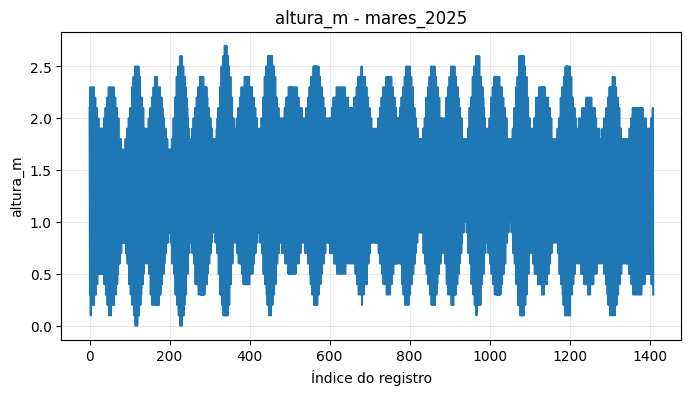

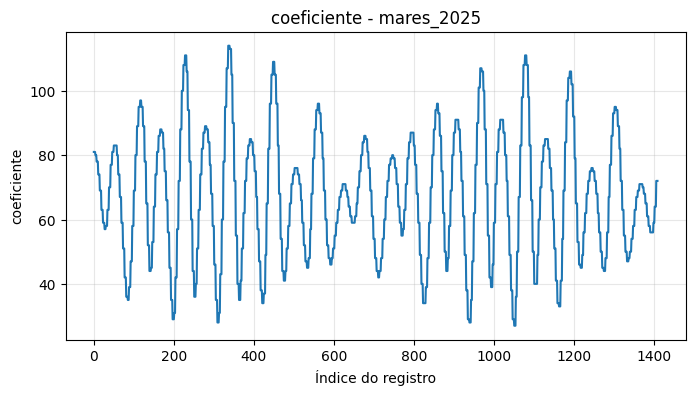

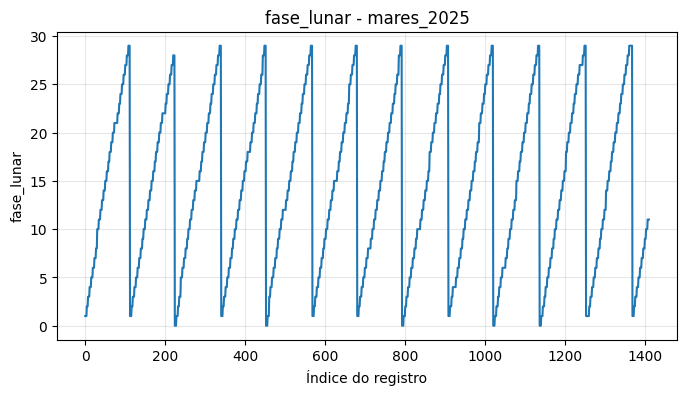

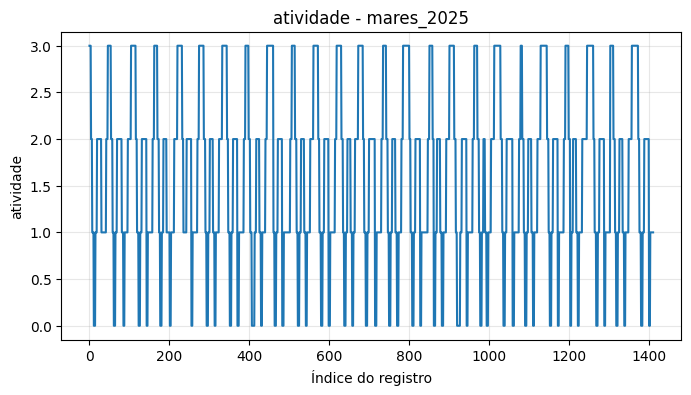


Gráficos de: mares_previsao.csv


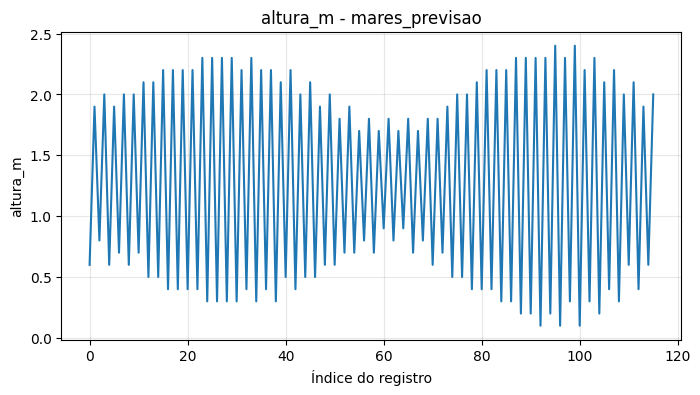

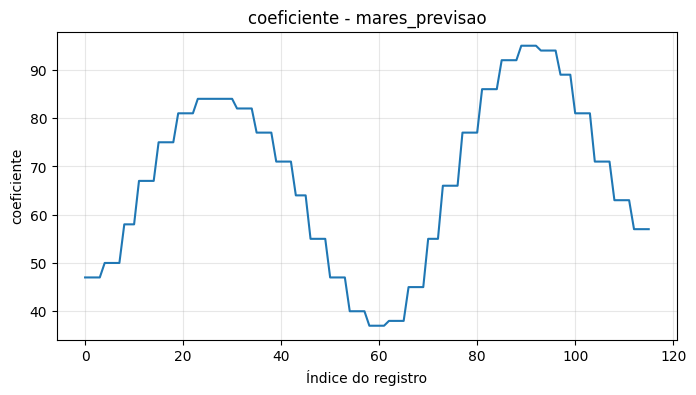

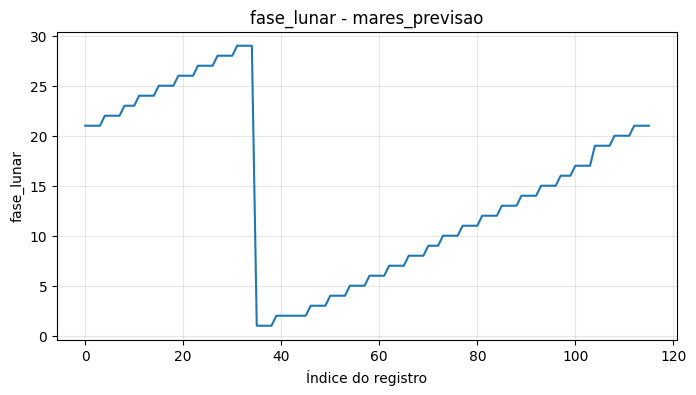

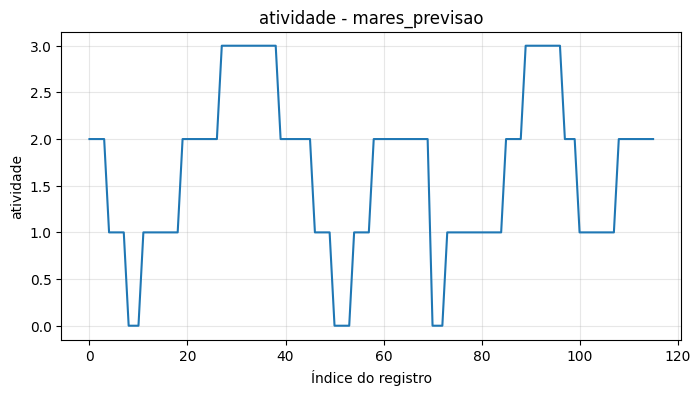


Gráficos de: ondas.csv


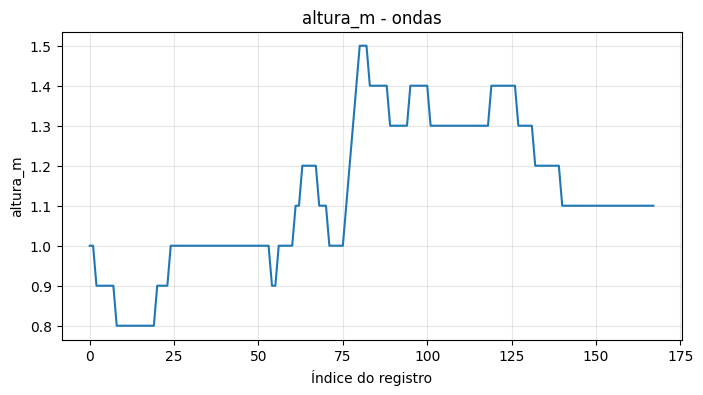


Gráficos de: vento.csv


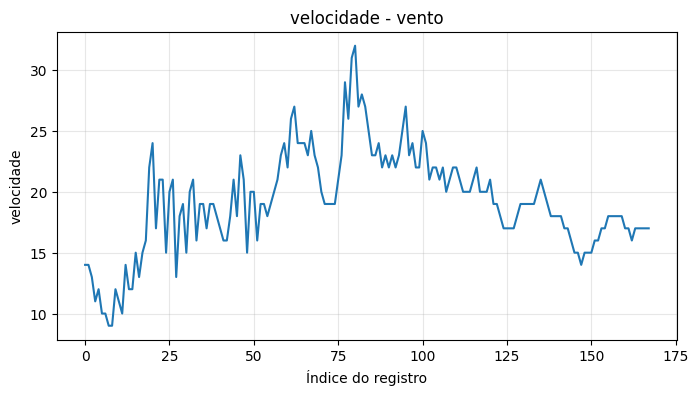

In [ ]:
for file in csv_files:

    df = pd.read_csv(file)

    print(f"\nGráficos de: {file.name}")

    colunas_numericas = df.select_dtypes(
        include="number"
    ).columns

    for column in colunas_numericas:

        plt.figure(figsize=(8, 4))

        plt.plot(df[column])

        plt.title(f"{column} - {file.stem}")
        plt.xlabel("Índice do registro")
        plt.ylabel(column)

        plt.grid(alpha=0.3)
        plt.show()
        #Antes estava fazendo um código que não levava em conta o tipo de dado de cada dataframe

## 4. Juntar as tabelas

Esta é a parte difícil, e ela tem mais de uma resposta certa.

As granularidades não batem: onda e vento são leituras horárias; maré são ~4
eventos por dia (os instantes de máxima e mínima). Para ter uma linha por hora
com as três informações você precisa decidir:

- Como levar a maré para a grade horária? Interpolar entre eventos? Repetir o
  último valor? Guardar apenas se a maré está subindo ou descendo? O que cada
  escolha assume sobre a curva real da maré — e onde essa suposição erra?
- Qual o tipo de junção? A previsão de onda e a de vento cobrem exatamente as
  mesmas horas? Se não, você mantém as horas incompletas ou corta?
- Que variáveis derivadas de tempo ajudam a responder a pergunta do projeto
  (dia da semana, período do dia, ...)?

Justifique as escolhas em markdown. Elas são a base das duas próximas etapas.

In [22]:
df_mares = pd.read_csv(data_path / "mares_2025.csv")
df_previsao = pd.read_csv(data_path / "mares_previsao.csv")
df_ondas = pd.read_csv(data_path / "ondas.csv")
df_vento = pd.read_csv(data_path / "vento.csv")

In [23]:
for df in [df_mares, df_previsao, df_ondas, df_vento]:
    df["data_hora"] = pd.to_datetime(
        df["data"].astype(str) + " " + df["hora"].astype(str),
        errors="coerce"
    )

In [28]:
df_ondas["data_hora"] = pd.to_datetime(
    df_ondas["data"].astype(str) + " " + df_ondas["hora"].astype(str)
)

df_vento["data_hora"] = pd.to_datetime(
    df_vento["data"].astype(str) + " " + df_vento["hora"].astype(str)
)

df_ambiente = pd.merge(
    df_ondas,
    df_vento,
    on="data_hora",
    how="inner",
    suffixes=("_onda", "_vento")
)

df_eventos_mare = pd.concat(
    [df_mares, df_previsao],
    ignore_index=True
)

df_eventos_mare = df_eventos_mare.sort_values("data_hora")

mare = (
    df_eventos_mare
    .drop_duplicates(subset="data_hora")
    .set_index("data_hora")["altura_m"]
    .sort_index()
)

horarios = pd.DatetimeIndex(
    df_ambiente["data_hora"].unique()
).sort_values()

mare_completa = mare.reindex(
    mare.index.union(horarios)
).sort_index()

mare_interpolada = mare_completa.interpolate(
    method="time",
    limit_area="inside"
)

df_mare_horaria = (
    mare_interpolada
    .reindex(horarios)
    .rename("altura_mare")
    .reset_index()
)

df_mare_horaria.rename(
    columns={"index": "data_hora"},
    inplace=True
)

df_final = pd.merge(
    df_ambiente,
    df_mare_horaria,
    on="data_hora",
    how="inner"
)

df_final = df_final.dropna(
    subset=["altura_mare"]
)

print(df_final.head())
print("Dimensões:", df_final.shape)

df_final["hora"] = df_final["data_hora"].dt.hour

df_final["dia_semana"] = df_final["data_hora"].dt.day_name()

df_final["mes"] = df_final["data_hora"].dt.month

def classificar_periodo(hora):
    if 5 <= hora < 12:
        return "Manhã"
    elif 12 <= hora < 18:
        return "Tarde"
    elif 18 <= hora < 24:
        return "Noite"
    else:
        return "Madrugada"

df_final["periodo_dia"] = df_final["hora"].apply(classificar_periodo)

    data_onda hora_onda direcao_onda  altura_m unidade_onda  \
0  2026-11-08     00:00            E       1.0            m   
1  2026-11-08     01:00            E       1.0            m   
2  2026-11-08     02:00            E       0.9            m   
3  2026-11-08     03:00            E       0.9            m   
4  2026-11-08     04:00            E       0.9            m   

            data_hora  data_vento hora_vento direcao_vento  velocidade  \
0 2026-11-08 00:00:00  2026-11-08      00:00           ENE        14.0   
1 2026-11-08 01:00:00  2026-11-08      01:00           ENE        14.0   
2 2026-11-08 02:00:00  2026-11-08      02:00           ENE        13.0   
3 2026-11-08 03:00:00  2026-11-08      03:00             E        11.0   
4 2026-11-08 04:00:00  2026-11-08      04:00             E        12.0   

  unidade_vento  altura_mare  
0          km/h     1.141823  
1          km/h     1.463539  
2          km/h     1.785255  
3          km/h     2.106971  
4          km/h     2

## 5. Visualizações voltadas à pergunta

Agora com a tabela junta: quando as condições coincidem?

- As horas de onda maior são as mesmas de vento mais fraco, ou elas se
  desencontram?
- Existe relação visível entre altura da maré e altura da onda?
- Quais dias e horas da janela se destacam?

Prefira poucos gráficos legíveis a muitos gráficos.

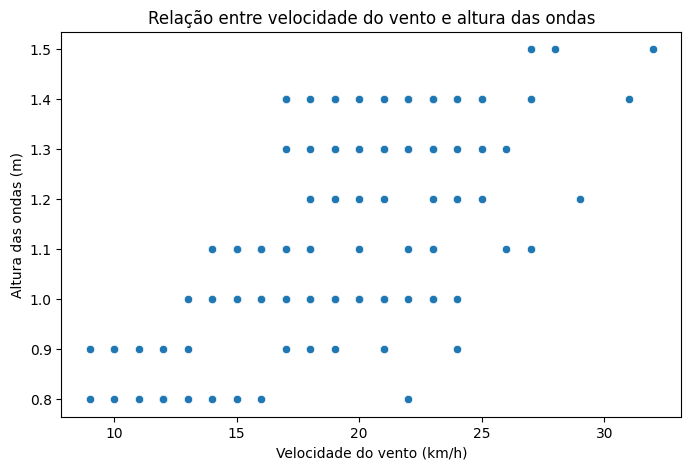

In [32]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_final,
    x="velocidade",
    y="altura_m"
)

plt.title("Relação entre velocidade do vento e altura das ondas")
plt.xlabel("Velocidade do vento (km/h)")
plt.ylabel("Altura das ondas (m)")
plt.show()

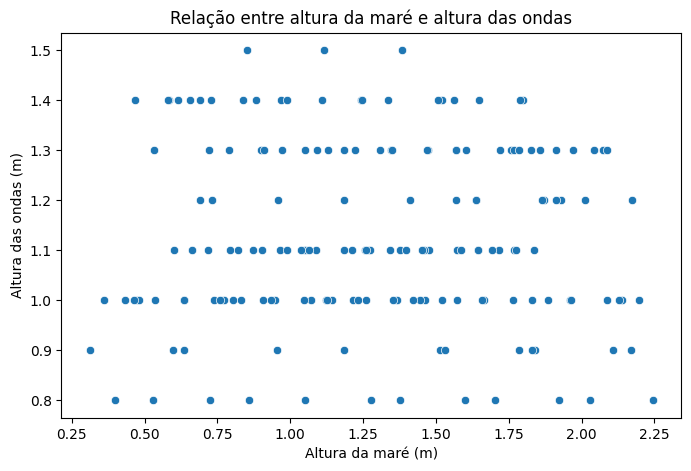

In [33]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_final,
    x="altura_mare",
    y="altura_m"
)

plt.title("Relação entre altura da maré e altura das ondas")
plt.xlabel("Altura da maré (m)")
plt.ylabel("Altura das ondas (m)")
plt.show()

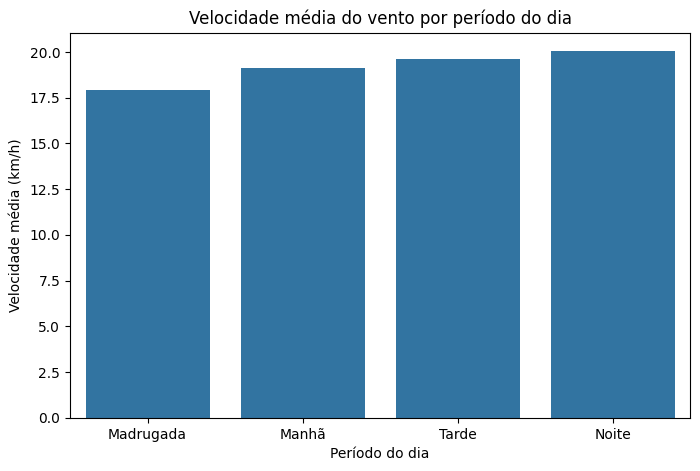

In [34]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_final,
    x="periodo_dia",
    y="velocidade",
    estimator="mean",
    errorbar=None,
    order=["Madrugada", "Manhã", "Tarde", "Noite"]
)

plt.title("Velocidade média do vento por período do dia")
plt.xlabel("Período do dia")
plt.ylabel("Velocidade média (km/h)")
plt.show()

## 6. Salvar o dataset processado

Grave o resultado em `../data/processed/dataset.csv`. A Etapa 3 lê esse
arquivo — se as colunas mudarem depois, o notebook de ML muda também.

In [35]:
from pathlib import Path

caminho_saida = Path("../data/processed")

caminho_saida.mkdir(parents=True, exist_ok=True)

df_final.to_csv(
    caminho_saida / "dataset.csv",
    index=False,
    encoding="utf-8"
)

## 7. Conclusões

Em texto, sem código:

1. O que os dados mostram sobre as condições da janela coletada?
   Mostram pouca variação de temperatura, vento e condições das ondas.
   
2. Que decisão de limpeza ou de junção você tomou que mais influencia o
   resultado, e por quê?
   Utilizei a interpolação linear para estimar a altura das marés nos horários
   que não existiam registros.Isso acontece porque os dados de ondas e vento possuem frequência horária, enquanto os dados de maré apresentam aproximadamente quatro registros por dia. Portanto, foi necessário estimar os valores intermediários para conseguir integrar as três tabelas.

3. O que esses dados **não** permitem afirmar?
Os dados não permitem afirmar Não permitem afirmar que o aumento da velocidade do vento causa diretamente o aumento da altura das ondas,
determinar com precisão a altura real da maré em todos os horários, pois parte dos valores foi interpolada e generalizar os resultados para todas as regiões costeiras, pois os dados representam apenas um local e um período de coleta.